Pairs Trading


Loosely based on Gatev, Goetzmann, and Rouwenhorst(2006), Pairs Trading: Performance of a Relative-Value Arbitrage Rule

http://www-stat.wharton.upenn.edu/~steele/Courses/434/434Context/PairsTrading/PairsTradingGGR.pdf

By Hong Kee Sul

Step 1. Import Modules

In [2]:
# !pip install yfinance

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn
import yfinance as yf
import statistics

from datetime import datetime
from dateutil.relativedelta import relativedelta

plt.style.use('fivethirtyeight')


Step 2. Set GICS sector, and Start Date

In [3]:

mySector = 'Consumer Staples'

sDate = '2022-01-01'
eDate =  (datetime.strptime(sDate, '%Y-%m-%d') + relativedelta(months=12)).strftime( '%Y-%m-%d')

print(sDate)
print(eDate)

2022-01-01
2023-01-01


Step 3. Generate List of S&P500 Firms


- Lists of S&P500 from wikipedia
  - https://en.wikipedia.org/wiki/List_of_S%26P_500_companies

- Load List of Tickers from the selected GICS sector

In [4]:
url = 'https://raw.githubusercontent.com/datasets/s-and-p-500-companies/master/data/constituents.csv'
import pandas as pd
gics = pd.io.parsers.read_csv(url)

In [5]:
#payload=pd.read_html('https://en.wikipedia.org/wiki/List_of_S%26P_500_companies')
#gics = payload[0]
gics2 = gics[gics['GICS Sector']==mySector]
myTickerList = list(gics2['Symbol'].values)

# Convert GICS ticker notation to Yahoo Finance notation (e.g., BF-B)
myTickerList = [ticker.replace('.', '-') for ticker in myTickerList]

print(len(myTickerList), myTickerList)

removeTickerList = ['KVUE', 'VYLR']

# Removed Ticker reasons: 
# KVUE: Went public on May 4, 2023; no historical stock prices for 2022.
# VYLR: Began trading on October 1, 2026, following its spin-off from Corteva; no historical stock prices for 2022.

for ticker in removeTickerList:
  try:
    myTickerList.remove(ticker)
  except:
    pass

print(len(myTickerList), myTickerList)


34 ['MO', 'ADM', 'BF-B', 'BG', 'CASY', 'CHD', 'CLX', 'KO', 'CL', 'STZ', 'COST', 'DG', 'DLTR', 'EL', 'GIS', 'HSY', 'HRL', 'KVUE', 'KDP', 'KMB', 'KHC', 'KR', 'MKC', 'MDLZ', 'MNST', 'PEP', 'PM', 'PG', 'SJM', 'SYY', 'TGT', 'TSN', 'VYLR', 'WMT']
32 ['MO', 'ADM', 'BF-B', 'BG', 'CASY', 'CHD', 'CLX', 'KO', 'CL', 'STZ', 'COST', 'DG', 'DLTR', 'EL', 'GIS', 'HSY', 'HRL', 'KDP', 'KMB', 'KHC', 'KR', 'MKC', 'MDLZ', 'MNST', 'PEP', 'PM', 'PG', 'SJM', 'SYY', 'TGT', 'TSN', 'WMT']


Step 4. Generating Cumulative Returns

- Load 1 year of Adj. Close Stock Price Data from Yahoo Finance

- Create Cumulative Return from the Adj. Close Price

In [6]:
import yfinance as yf
import pandas as pd

# 1. Download data
# auto_adjust=False forces yfinance to return 'Adj Close' (fixing the FutureWarning)
# threads=True speeds up the download for many tickers
data = yf.download(myTickerList, start=sDate, end=eDate, group_by='column', auto_adjust=False, threads=True)

# 2. Select 'Adj Close' safely
if 'Adj Close' in data.columns:
    data = data['Adj Close']
else:
    # Fallback if only one level exists or 'Adj Close' is missing
    print("Warning: 'Adj Close' not found. Using 'Close' or checking data format.")
    # Attempt to use 'Close' if Adj Close is missing (common with auto_adjust=True)
    if 'Close' in data.columns:
        data = data['Close']

# 3. Clean Data
# Drop rows where ALL tickers are missing (e.g., holidays)
data = data.dropna(how='all')
# Drop columns (tickers) that have NO data at all (like 'FOX' in your error)
data = data.dropna(axis='columns', how='all')

# 4. Calculate Cumulative Returns
if not data.empty:
    # Vectorized calculation (faster than loop)
    data_CumRet = data / data.iloc[0]
    print(data_CumRet.head())
    print(data_CumRet.tail())
else:
    print("Error: DataFrame is empty. Check your dates or ticker symbols.")

[*********************100%***********************]  32 of 32 completed

Ticker           ADM      BF-B        BG      CASY       CHD        CL  \
Date                                                                     
2022-01-03  1.000000  1.000000  1.000000  1.000000  1.000000  1.000000   
2022-01-04  1.018560  0.997765  1.008750  0.988443  1.001081  1.003310   
2022-01-05  1.010605  1.003632  1.002775  0.981093  1.008160  1.007448   
2022-01-06  1.019591  0.967035  1.025718  0.999290  1.009832  1.000827   
2022-01-07  1.028281  0.951949  1.035322  0.996198  1.018582  0.998227   

Ticker           CLX      COST        DG      DLTR  ...        MO       PEP  \
Date                                                ...                       
2022-01-03  1.000000  1.000000  1.000000  1.000000  ...  1.000000  1.000000   
2022-01-04  1.003773  0.995624  0.992441  0.995325  ...  1.022097  1.001445   
2022-01-05  1.014291  0.970373  0.992866  0.994546  ...  1.013967  1.004856   
2022-01-06  1.020637  0.970161  1.001359  1.011688  ...  1.025849  1.005087   
2022-01

Step 5. Define the find_pairs function

- From 32 stocks, the number of possible pairs is
  - 32 C 2 = 32 x 31 / 2 = 496

- Role of the find_pairs function:

    - For all possible pair of Stocks,

    - Calculate the sum of squared spread(error) between the stock cumulative returns for each pair




In [7]:
MAX_SSE = 0.75

def calcSse(data1, data2):
  if len(data1)!= len(data2):
    print('err in rmse data length')
    return None
  else:
    sum = 0
    for i, d1 in enumerate(data1):
      sum += (d1 - data2.iloc[i])**2
    return sum

def find_pairs(data):
    n = data.shape[1]
    score_matrix = np.zeros((n, n))
    keys = data.keys()
    pairs = []
    for i in range(n):
        score_matrix[i, i] = MAX_SSE
        for j in range(i+1, n):
            S1 = data[keys[i]]
            S2 = data[keys[j]]
            sum = calcSse(S1, S2)
            pairs.append([keys[i], keys[j], sum])
            score_matrix[i, j] = sum
            score_matrix[j, i] = MAX_SSE
    return (score_matrix, pairs)



Step 6. Execute find_pairs function, and show the heatmap of the results

- Show a heatmap of the SSE(Sum of Squared Errors), excluding the one that have SSE over MAX_SSE

<Axes: >

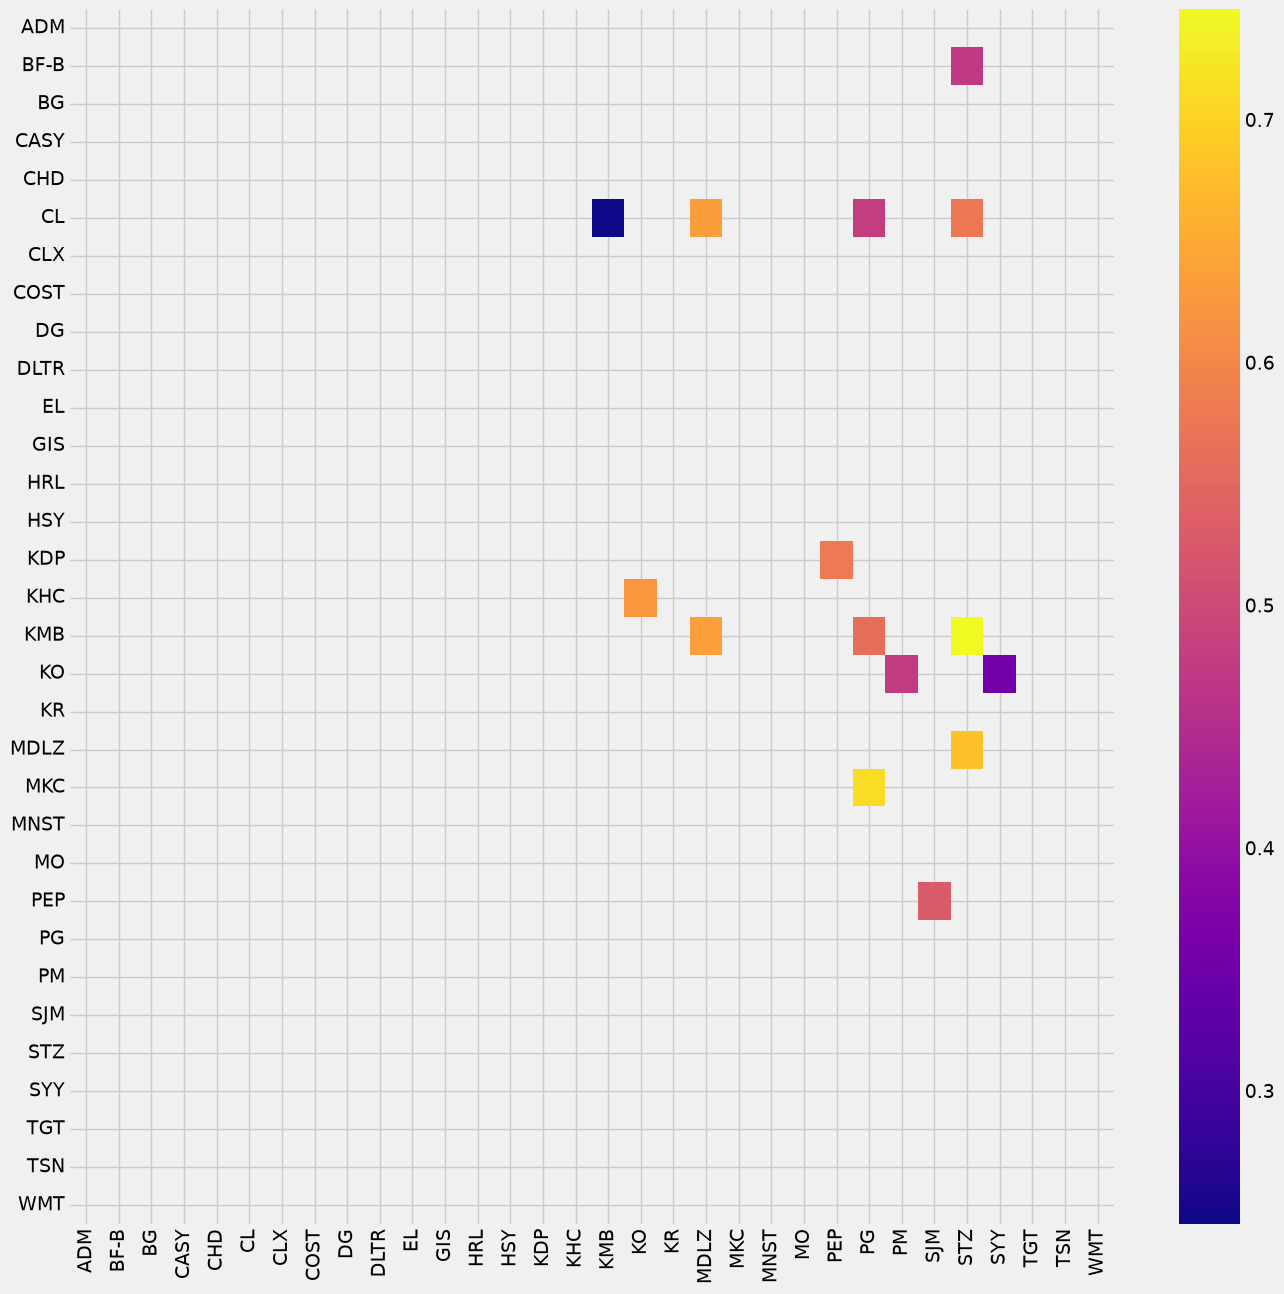

In [8]:
scoreData, pairsData = find_pairs(data_CumRet)

fig, ax = plt.subplots(figsize=(15,15))
seaborn.heatmap(scoreData, xticklabels = data_CumRet.columns, yticklabels = data_CumRet.columns, cmap = 'plasma', mask = ( (scoreData >= MAX_SSE)), ax=ax)



Step 7. Print Results
- Show the combination(pair) of stocks that have a SSE lower than MAX_SSE, ordered by SSE

In [9]:
pairsData.sort(key=lambda x: float(x[2]))

print(f"{'Rank':<6}{'Ticker 1':<12}{'Ticker 2':<12}{'SSE':>10}")
print("-" * 40)

rank = 1
for pData in pairsData:
    if float(pData[2]) < MAX_SSE:
        print(f"{rank:<6}{pData[0]:<12}{pData[1]:<12}{float(pData[2]):>10.4f}")
        rank += 1

Rank  Ticker 1    Ticker 2           SSE
----------------------------------------
1     CL          KMB             0.2450
2     KO          SYY             0.3527
3     BF-B        STZ             0.4721
4     KO          PM              0.4745
5     CL          PG              0.4800
6     PEP         SJM             0.5292
7     KMB         PG              0.5607
8     CL          STZ             0.5769
9     KDP         PEP             0.5797
10    KHC         KO              0.6235
11    CL          MDLZ            0.6323
12    KMB         MDLZ            0.6351
13    MDLZ        STZ             0.6807
14    MKC         PG              0.7108
15    KMB         STZ             0.7455


Step 8. Choosing Pairs

We choose five pairs from the 15 lowest-SSE candidates using qualitative
judgement and reasoning, alongside their historical price proximity.

Our selection considers:

- **Related businesses:** whether the companies operate in similar
  industries or have comparable business models.
- **Product and customer similarity:** whether they offer related
  products, serve similar customers, or share demand drivers.
- **Reduced overlap:** where practical, avoid repeatedly selecting
  the same stocks to limit concentration and broaden the analysis.
- **Important differences:** consider differences in product mix,
  geographic markets, and company-specific risks that could cause
  their stock prices to diverge.

The final selection balances these considerations rather than simply
taking the five pairs with the lowest SSE. 

In [10]:
# Top 15 candidate pairs based on 2022 formation-period SSE.
# Columns: ticker1, ticker2, SSE
candidatePairs = [
    ('CL',   'KMB',  0.24496665684799612),
    ('KO',   'SYY',  0.35265619329720677),
    ('BF-B', 'STZ',  0.47213149777046826),
    ('KO',   'PM',   0.474472206873784),
    ('CL',   'PG',   0.47998544296973356),
    ('PEP',  'SJM',  0.5291763049139994),
    ('KMB',  'PG',   0.5607244374316616),
    ('CL',   'STZ',  0.5768699631879404),
    ('KDP',  'PEP',  0.5797321701781919),
    ('KHC',  'KO',   0.6235422192101391),
    ('CL',   'MDLZ', 0.6322794711095582),
    ('KMB',  'MDLZ', 0.6350571750193377),
    ('MDLZ', 'STZ',  0.680748487406615),
    ('MKC',  'PG',   0.7107838920915746),
    ('KMB',  'STZ',  0.7454636296698913),
]

# 5 Selected Pairs from the 15 Candidates (Qualitative Choices)
selectedPairs = [
    ('CL', 'PG'),
    ('KMB', 'PG'),
    ('KDP', 'PEP'),
    ('BF-B', 'STZ'),
    ('PEP', 'SJM'),
]

Step 9. Compare Adj. Close prices

- Now let's visualize the data - Adj. Close Price Comparison, for the first pair (CL-PG)

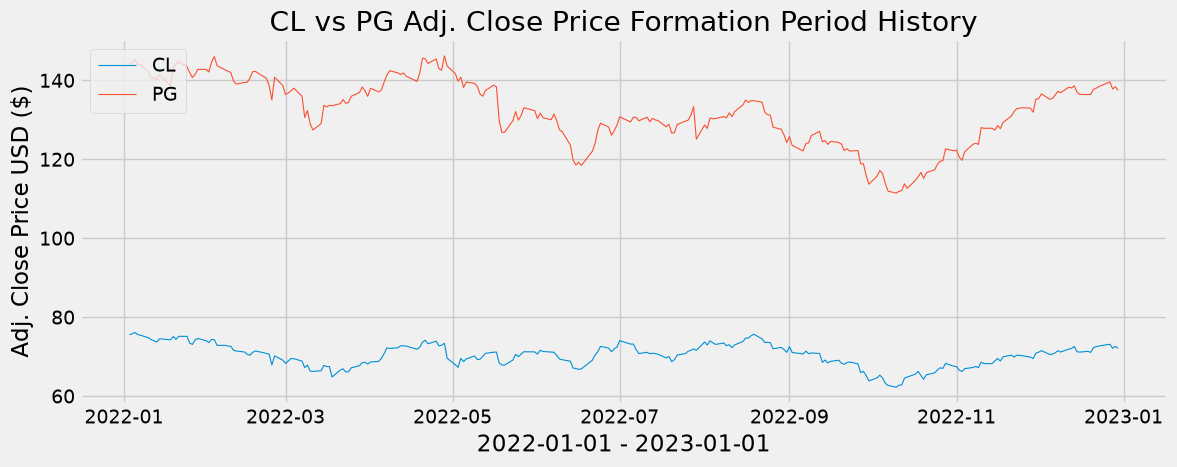

In [16]:
ticker1, ticker2 = selectedPairs[0]  # CL–PG

plt.figure(figsize=(12.5, 4.5))
plt.plot(data[ticker1], label = ticker1, linewidth = 0.8)
plt.plot(data[ticker2], label = ticker2, linewidth = 0.8)
plt.title(ticker1+ ' vs ' + ticker2 + ' Adj. Close Price Formation Period History')
plt.xlabel(sDate+" - "+eDate)
plt.ylabel('Adj. Close Price USD ($)')
plt.legend(loc='upper left')
plt.show()

Step 10. Compare Cumulative Returns

- Now let's visualize the data - Cum Return Comparison, for the first pair ('CL'-'PG')

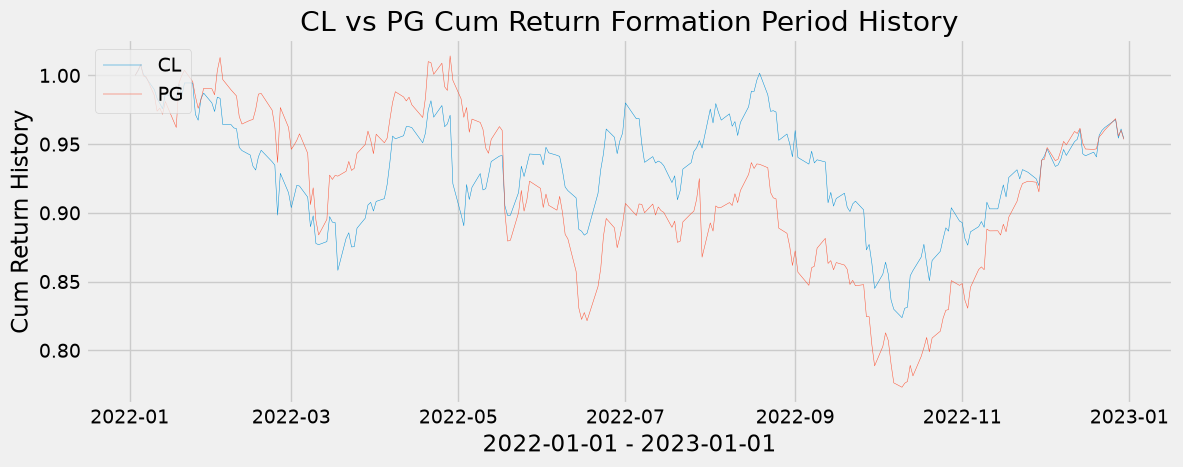

In [18]:


plt.figure(figsize=(12.5, 4.5))
plt.plot(data_CumRet[ticker1], label = ticker1, linewidth = 0.35)
plt.plot(data_CumRet[ticker2], label = ticker2, linewidth = 0.35)
plt.title(ticker1+ ' vs ' + ticker2 + ' Cum Return Formation Period History')
plt.xlabel(sDate+" - "+eDate)
plt.ylabel('Cum Return History')
plt.legend(loc='upper left')
plt.show()


We see that this pair's stock returns has been very hightly correlated for the 1 year period.

Step 11. Calculate the STDEV of the stock return spread.
- A quantitative measure of how similar the stocks are


In [20]:
stdev = statistics.stdev(data_CumRet[ticker1]-data_CumRet[ticker2])
print('Stdev of spread in the Formation Period is: ', stdev)

Stdev of spread in the Formation Period is:  0.0410535738876316
